Узнает ли MLP цифру на негативе?
Я сравниваю два способа повысить устойчивость классификатора к смене фона: заменить ReLU на обучаемую PReLU или показать модели при обучении цифры обеих полярностей. У каждой тестовой картинки есть пара - её негатив с той же меткой. Это позволяет проверить, как часто смена фона меняет ответ именно на той же цифре.

**Гипотеза.** Обучение на обеих полярностях даст больший выигрыш на негативах, чем одна замена активации. Контрольная модель содержит два линейных слоя без активации. Их композиция задаёт аффинную функцию. При инверсии центрированного изображения меняется знак его пикселей. Для линейного классификатора это обращает знак вклада пикселей в каждый логит, а смещения остаются прежними.

**Данные.** В ноутбук встроены 1797 рукописных цифр 8×8 из UCI Optical Recognition of Handwritten Digits (копия набора load_digits). Для выполнения нужны PyTorch и matplotlib для рисунков.

In [ ]:
from sklearn.datasets import load_digits
import torch
from torch import nn
import matplotlib.pyplot as plt
digits = load_digits()
x = torch.tensor(digits.data, dtype=torch.float32) / 8 - 1
y = torch.tensor(digits.target, dtype=torch.long)
print("Изображения:", tuple(x.shape), "Классы:", y.unique().tolist())

Изображения: (1797, 64) Классы: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


Разбиение и изображения

От каждого класса оставляю около 20% для итоговой проверки. Негатив создаю после разбиения: обе версии изображения всегда относятся к одной выборке. Пиксели лежат в диапазоне от −1 до 1, поэтому негатив получается умножением на −1. Все настройки обучения фиксирую заранее.

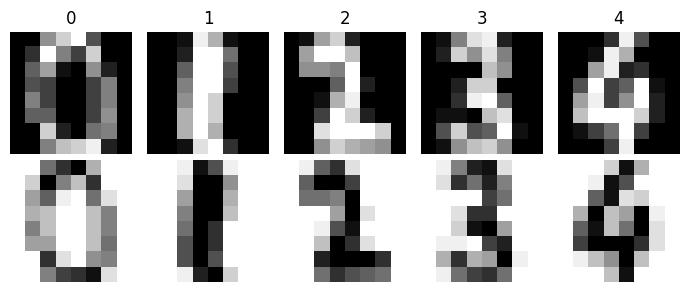

In [ ]:
split_rng = torch.Generator().manual_seed(42)
train_parts, test_parts = [], []
for digit in range(10):
    ids = torch.where(y == digit)[0]
    ids = ids[torch.randperm(len(ids), generator=split_rng)]
    k = round(0.2 * len(ids))
    test_parts.append(ids[:k])
    train_parts.append(ids[k:])
train, test = torch.cat(train_parts), torch.cat(test_parts)
xt, yt = x[test], y[test]
fig, axes = plt.subplots(2, 5, figsize=(7, 3))
for j in range(5):
    idx = test_parts[j][0]
    for row, sign in enumerate((1, -1)):
        axes[row, j].imshow(sign * x[idx].reshape(8, 8), cmap="gray", vmin=-1, vmax=1)
        axes[row, j].axis("off")
    axes[0, j].set_title(str(y[idx].item()))
plt.tight_layout()
plt.show()

Модель и обучение

Для всех сетей беру слои 64 - 32 - 10, Adam и кросс-энтропию. В PReLU положительная ветвь равна входу, а на отрицательной действует обучаемый коэффициент. Проверяю его градиент на трёх числах. В смешанном режиме с вероятностью 1/2 меняю полярность каждого обучающего примера. Число шагов и порядок объектов совпадают для всех вариантов одного запуска.

In [ ]:
class MyPReLU(nn.Module):
    def __init__(self):
        super().__init__()
        self.a = nn.Parameter(torch.tensor(0.25))

    def forward(self, values):
        return torch.where(values >= 0, values, self.a * values)

probe = MyPReLU()
probe(torch.tensor([-3., -1., 2.])).sum().backward()
assert probe.a.grad.item() == -4

def fit(activation, mixed, seed):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(64, 32), activation(), nn.Linear(32, 10))
    opt = torch.optim.Adam(net.parameters(), lr=0.005)
    criterion = nn.CrossEntropyLoss()
    order_rng = torch.Generator().manual_seed(seed + 100)
    sign_rng = torch.Generator().manual_seed(seed + 200)
    for epoch in range(30):
        order = train[torch.randperm(len(train), generator=order_rng)]
        for batch in order.split(64):
            inputs = x[batch]
            if mixed:
                signs = 2 * torch.randint(0, 2, (len(batch), 1), generator=sign_rng) - 1
                inputs = inputs * signs
            opt.zero_grad()
            loss = criterion(net(inputs), y[batch])
            loss.backward()
            opt.step()
    return net.eval()

Результаты

Повторяю каждый вариант с тремя начальными инициализациями при одном разбиении. Считаю процент верных ответов отдельно для оригиналов и негативов. Третья метрика - доля изображений, для которых **обе** версии распознаны правильно. Формат таблицы - среднее ± стандартное отклонение между запусками, в процентных пунктах.

In [ ]:
activations = {"Без активации": nn.Identity, "ReLU": nn.ReLU, "PReLU": MyPReLU}
scores, predictions = {}, {}
for name, activation in activations.items():
    for mixed in (False, True):
        values, slopes = [], []
        for seed in (1, 2, 3):
            net = fit(activation, mixed, seed)
            with torch.no_grad():
                normal = net(xt).argmax(1)
                negative = net(-xt).argmax(1)
            ok, inv = normal == yt, negative == yt
            values.append([100 * v.float().mean().item() for v in (ok, inv, ok & inv)])
            if name == "PReLU":
                slopes.append(round(net[1].a.item(), 3))
            if seed == 1:
                predictions[name, mixed] = (normal, negative)
        scores[name, mixed] = torch.tensor(values)
        means, spreads = scores[name, mixed].mean(0), scores[name, mixed].std(0)
        numbers = " | ".join(f"{m:.1f} ± {s:.1f}" for m, s in zip(means, spreads))
        mode = "обе полярности" if mixed else "оригиналы"
        print(f"{name:14} | {mode:15} | {numbers}", "  a =" + str(slopes) if slopes else "")
print("Столбцы: модель | обучение | оригиналы, % | негативы, % | обе верны, %")

Без активации  | оригиналы       | 96.4 ± 0.7 | 0.0 ± 0.0 | 0.0 ± 0.0 
Без активации  | обе полярности  | 12.2 ± 8.6 | 11.3 ± 9.5 | 0.0 ± 0.0 
ReLU           | оригиналы       | 96.9 ± 1.2 | 3.5 ± 2.5 | 3.3 ± 2.4 
ReLU           | обе полярности  | 96.9 ± 1.2 | 95.8 ± 0.6 | 95.3 ± 1.0 
PReLU          | оригиналы       | 96.6 ± 0.7 | 0.0 ± 0.0 | 0.0 ± 0.0   a =[0.33, 0.415, 0.264]
PReLU          | обе полярности  | 96.9 ± 0.7 | 96.9 ± 0.8 | 96.7 ± 1.0   a =[-0.8, -0.798, -0.8]
Столбцы: модель | обучение | оригиналы, % | негативы, % | обе верны, %


Что сильнее изменило результат?

Сравниваю два изменения относительно одной отправной точки - ReLU, обученной на оригиналах. Ниже выводятся разности в точности на негативах. На рисунке показаны первые доступные случаи, когда исходная ReLU узнала оригинал и ошиблась на негативе. В подписях сравниваю прогнозы двух режимов обучения ReLU на этом негативе.

Замена ReLU на PReLU: -3.5 п.п.
Добавление негативов при обучении ReLU: +92.3 п.п.
Гипотеза поддерживается средними значениями: да


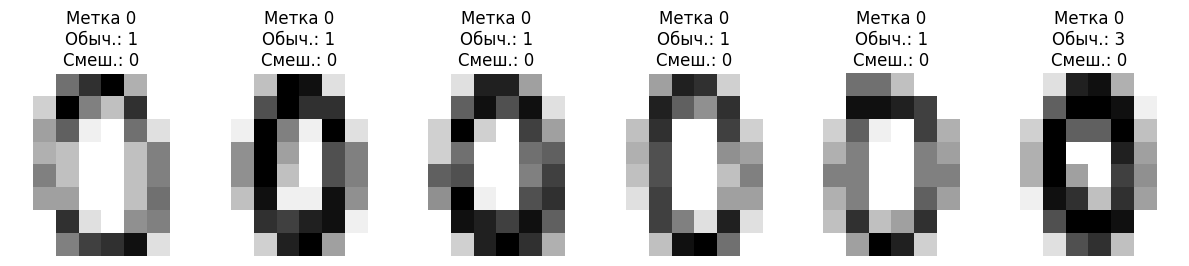

In [ ]:
base = scores["ReLU", False][:, 1]
delta_act = (scores["PReLU", False][:, 1] - base).mean().item()
delta_data = (scores["ReLU", True][:, 1] - base).mean().item()
print(f"Замена ReLU на PReLU: {delta_act:+.1f} п.п.")
print(f"Добавление негативов при обучении ReLU: {delta_data:+.1f} п.п.")
print("Гипотеза поддерживается средними значениями:", "да" if delta_data > delta_act else "нет")
normal, negative = predictions["ReLU", False]
mixed_negative = predictions["ReLU", True][1]
ids = torch.where((normal == yt) & (negative != yt))[0][:6]
if len(ids):
    fig, axes = plt.subplots(1, len(ids), squeeze=False, figsize=(2 * len(ids), 2.5))
    for ax, i in zip(axes[0], ids):
        ax.imshow(-xt[i].reshape(8, 8), cmap="gray", vmin=-1, vmax=1)
        ax.set_title(f"Метка {yt[i].item()}\nОбыч.: {negative[i].item()}\nСмеш.: {mixed_negative[i].item()}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("В выбранном запуске таких ошибок нет.")

**Границы вывода.** Сравнение относится к полной инверсии яркости и одному разбиению. PReLU действует на выход первого линейного слоя, поэтому сохранение отрицательной ветви само по себе не гарантирует устойчивости к смене полярности входа. Примеры ошибок иллюстрируют механизм сравнения; общий результат оцениваю по всем тестовым парам.